<a href="https://colab.research.google.com/github/abdoul-create/rendement-mil/blob/main/etape3_exploration_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Étape 3 : assemblage des données et exploration
**Projet :** prédiction des rendements du mil au Niger (Maradi, Zinder, Tahoua, Tillabéri) à mi-saison (15 août)

Ce notebook :
1. charge les quatre fichiers de données (rendements INS, pluie CHIRPS, NDVI MODIS, séquence sèche) ;
2. les assemble en un seul tableau (une ligne par région et par année) ;
3. construit les écarts à la normale ;
4. explore les relations entre variables et rendement (figures sauvegardées dans `outputs/`) ;
5. mesure la performance de la **baseline** (moyenne historique), qui servira de référence à l'étape 4.

**Fichiers attendus dans le dossier `data/`** :
`rendements_mil_niger_2015_2024.xlsx`, `chirps_regions.csv`, `ndvi_regions.csv`, `secheresse_regions.csv`

## 0. Règle anti-fuite d'information
La prédiction se fait **à la mi-août**. Une variable n'a le droit d'entrer dans le modèle que si elle est connue à cette date.

- Autorisées : pluie de mai, juin, juillet ; pluie cumulée du 1er mai au 15 août ; jours de pluie jusqu'au 15 août ; NDVI des composites commençant au plus tard le 31 juillet ; séquence sèche du 1er juin au 15 août.
- **Interdites : la pluie mensuelle d'août (elle couvre tout le mois, donc aussi la 2e quinzaine), de septembre et d'octobre.** Elles servent uniquement à l'exploration.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA_DIR = "data"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

CLES = ["region", "annee"]
REGIONS_ENTRAINEMENT = ["Diffa", "Dosso", "Maradi", "Tahoua", "Tillabéri", "Zinder"]
REGIONS_EVALUATION = ["Maradi", "Zinder", "Tahoua", "Tillabéri"]
CIBLE = "rendement_calcule_kg_ha"

# Variables autorisées à la mi-août
FEATURES = [
    "pluie_cumul_1mai_15aout_mm", "jours_pluie_1mai_15aout",
    "pluie_mois_05_mm", "pluie_mois_06_mm", "pluie_mois_07_mm",
    "ndvi_mai_moy", "ndvi_juin_moy", "ndvi_juil_moy", "ndvi_max_juin_juil", "ndvi_fin_juil",
    "plus_longue_sequence_seche_jours",
]
# Variables interdites pour le modèle (exploration seulement)
INTERDITES = ["pluie_mois_08_mm", "pluie_mois_09_mm", "pluie_mois_10_mm"]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Chargement des données

In [2]:
rend = pd.read_excel(f"{DATA_DIR}/rendements_mil_niger_2015_2024.xlsx", sheet_name="donnees")
rend = rend[CLES + ["rendement_publie_kg_ha", "rendement_calcule_kg_ha", "alerte"]]
chirps = pd.read_csv(f"{DATA_DIR}/chirps_regions.csv")
ndvi = pd.read_csv(f"{DATA_DIR}/ndvi_regions.csv")
seche = pd.read_csv(f"{DATA_DIR}/secheresse_regions.csv")

for nom, d in [("rendements", rend), ("CHIRPS", chirps), ("NDVI", ndvi), ("séquence sèche", seche)]:
    print(f"{nom:16s} {d.shape[0]:3d} lignes | valeurs manquantes : {int(d.isna().sum().sum())}")

rendements        80 lignes | valeurs manquantes : 0
CHIRPS            80 lignes | valeurs manquantes : 0
NDVI              80 lignes | valeurs manquantes : 0
séquence sèche    80 lignes | valeurs manquantes : 0


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Assemblage en un seul tableau

In [4]:
climat = chirps.merge(ndvi, on=CLES).merge(seche, on=CLES)
df = rend.merge(climat, on=CLES, how="left")

assert len(df) == 80, "On attend 8 régions x 10 ans = 80 lignes"
assert df[FEATURES + INTERDITES].isna().sum().sum() == 0, "Valeurs manquantes dans les variables"
print(df.shape)
df.head()

(80, 19)


,region,annee,rendement_publie_kg_ha,rendement_calcule_kg_ha,alerte,jours_pluie_1mai_15aout,pluie_cumul_1mai_15aout_mm,pluie_mois_05_mm,pluie_mois_06_mm,pluie_mois_07_mm,pluie_mois_08_mm,pluie_mois_09_mm,pluie_mois_10_mm,ndvi_fin_juil,ndvi_juil_moy,ndvi_juin_moy,ndvi_mai_moy,ndvi_max_juin_juil,plus_longue_sequence_seche_jours
0,Agadez,2015,467,466.666667,ok,6.0,32.1,6.3,2.2,8.3,23.2,9.2,0.3,0.1005,0.1019,0.1026,0.1014,0.1063,54.3114
1,Agadez,2016,438,438.596491,ok,6.1,29.7,6.3,4.7,12.4,14.5,3.7,0.1,0.1060,0.1047,0.0978,0.0996,0.1093,46.8152
2,Agadez,2017,779,776.223776,ok,6.1,28.7,7.6,5.1,8.7,15.1,3.4,0.1,0.1062,0.1060,0.0991,0.0997,0.1093,50.8572
3,Agadez,2018,634,633.986928,ok,7.4,38.6,6.7,6.0,10.5,25.4,7.8,0.5,0.1056,0.1044,0.1003,0.1023,0.1085,48.1522
4,Agadez,2019,431,430.769231,ok,5.4,25.0,5.9,4.2,9.4,25.6,3.8,0.8,0.1041,0.1034,0.1022,0.1013,0.1068,53.1229


## 3. Écarts à la normale
Une variable brute (par exemple 300 mm de pluie) ne veut pas dire la même chose à Dosso et à Zinder. On calcule donc, pour chaque région, l'écart relatif à sa **moyenne** : `valeur / moyenne de la région - 1`.

⚠ **Attention pour l'étape 4 (modélisation)** : ici, la moyenne est calculée sur toutes les années, ce qui est acceptable pour explorer. Lors de l'entraînement, la normale devra être recalculée **uniquement sur les années d'entraînement**, sinon on laisse fuiter de l'information sur l'année testée.

In [5]:
for col in FEATURES + INTERDITES + [CIBLE]:
    df[col + "_anom"] = df[col] / df.groupby("region")[col].transform("mean") - 1

df[CIBLE + "_anom"].describe().round(3)

,rendement_calcule_kg_ha_anom
count,80.000
mean,-0.000
std,0.196
min,-0.742
25%,-0.075
50%,0.035
75%,0.122
max,0.443


## 4. Statistiques descriptives des rendements

In [6]:
resume = (df.groupby("region")[CIBLE]
            .agg(["mean", "std", "min", "max"])
            .round(0)
            .assign(cv_pct=lambda t: (100 * t["std"] / t["mean"]).round(0)))
resume

,mean,std,min,max,cv_pct
region,,,,,
Agadez,538.0,125.0,370.0,776.0,23.0
Diffa,400.0,86.0,264.0,526.0,22.0
Dosso,559.0,81.0,414.0,702.0,14.0
Maradi,565.0,59.0,463.0,655.0,10.0
Niamey,479.0,167.0,123.0,610.0,35.0
Tahoua,530.0,88.0,303.0,638.0,17.0
Tillabéri,428.0,86.0,232.0,527.0,20.0
Zinder,467.0,60.0,318.0,539.0,13.0


**Lecture :** `cv_pct` est le coefficient de variation (écart-type / moyenne). Plus il est élevé, plus les rendements d'une région varient d'une année à l'autre, donc plus la prédiction est difficile.

## 5. Figure 1 : évolution des rendements par région

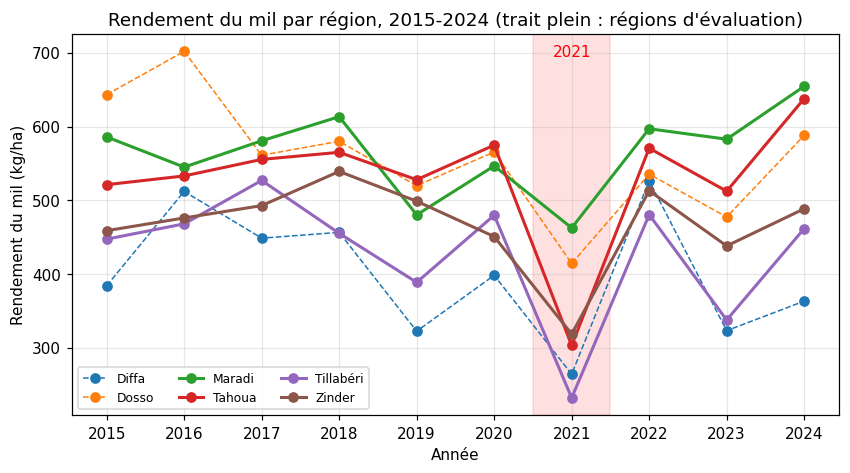

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in REGIONS_ENTRAINEMENT:
    d = df[df.region == r].sort_values("annee")
    ax.plot(d.annee, d[CIBLE], marker="o", label=r, lw=2 if r in REGIONS_EVALUATION else 1,
            ls="-" if r in REGIONS_EVALUATION else "--")
ax.axvspan(2020.5, 2021.5, color="red", alpha=0.12)
ax.text(2021, ax.get_ylim()[1] * 0.98, "2021", ha="center", va="top", color="red")
ax.set_xlabel("Année"); ax.set_ylabel("Rendement du mil (kg/ha)")
ax.set_title("Rendement du mil par région, 2015-2024 (trait plein : régions d'évaluation)")
ax.set_xticks(range(2015, 2025)); ax.legend(ncol=3, fontsize=8)
fig.savefig(f"{OUT_DIR}/fig1_rendements_par_region.png", bbox_inches="tight", dpi=150)
plt.show()

## 6. Figure 2 : pluie, NDVI et séquence sèche par région

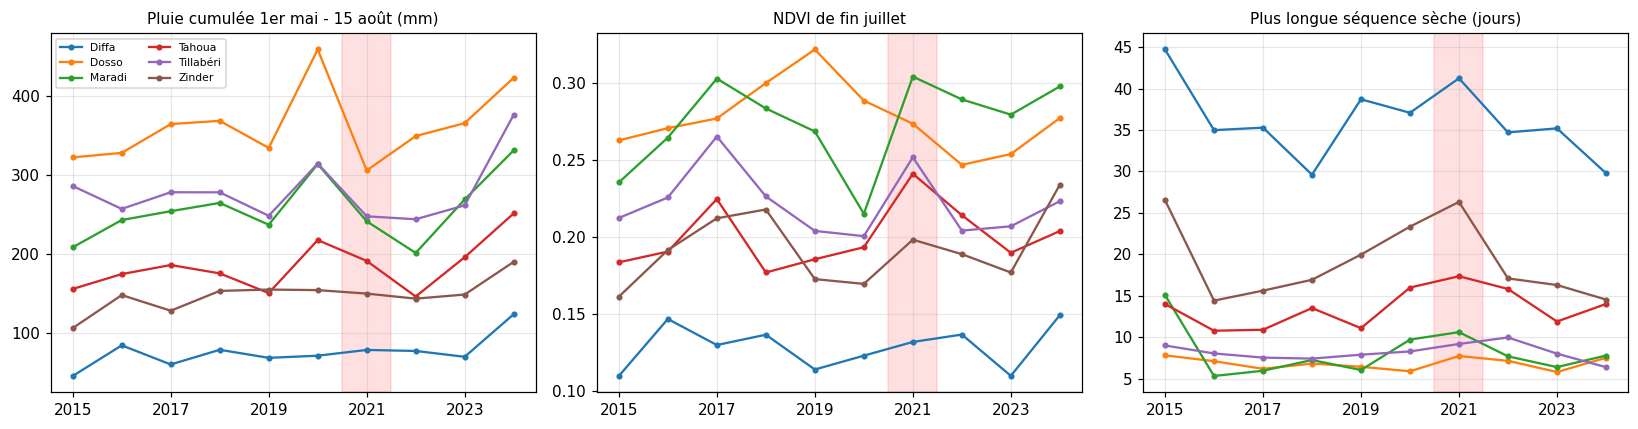

In [8]:
panneaux = [("pluie_cumul_1mai_15aout_mm", "Pluie cumulée 1er mai - 15 août (mm)"),
            ("ndvi_fin_juil", "NDVI de fin juillet"),
            ("plus_longue_sequence_seche_jours", "Plus longue séquence sèche (jours)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, titre) in zip(axes, panneaux):
    for r in REGIONS_ENTRAINEMENT:
        d = df[df.region == r].sort_values("annee")
        ax.plot(d.annee, d[col], marker="o", ms=3, label=r)
    ax.axvspan(2020.5, 2021.5, color="red", alpha=0.12)
    ax.set_title(titre, fontsize=10); ax.set_xticks(range(2015, 2025, 2))
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/fig2_variables_explicatives.png", bbox_inches="tight", dpi=150)
plt.show()

## 7. Figure 3 : écart de la variable vs écart du rendement

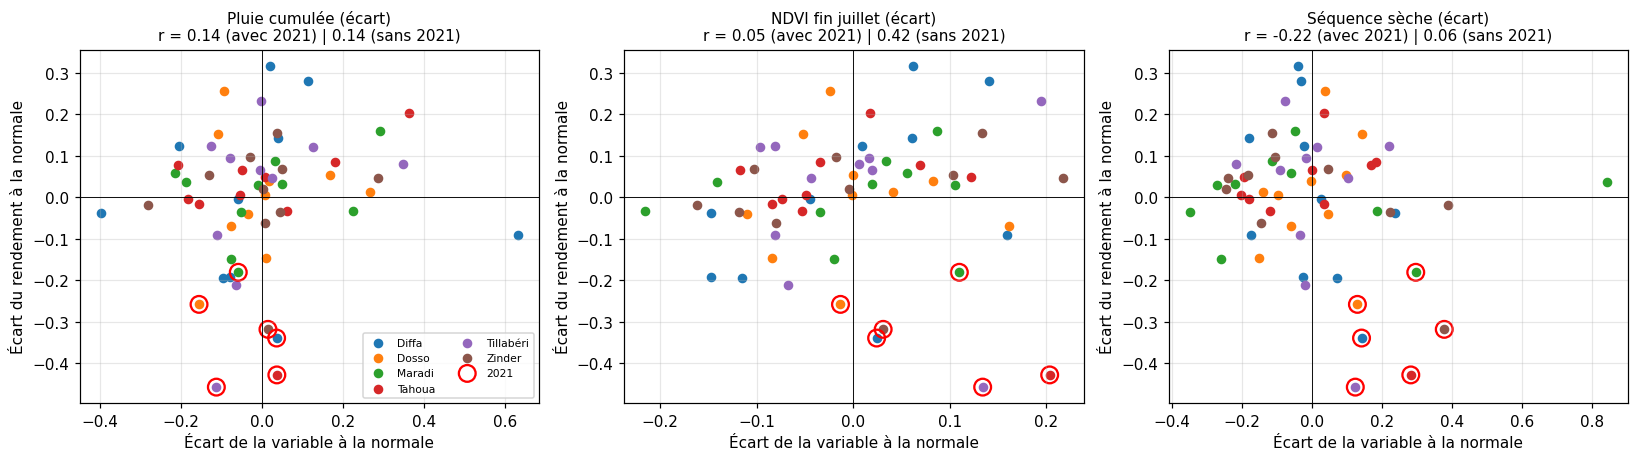

In [9]:
d6 = df[df.region.isin(REGIONS_ENTRAINEMENT)].copy()
vars_fig = [("pluie_cumul_1mai_15aout_mm", "Pluie cumulée (écart)"),
            ("ndvi_fin_juil", "NDVI fin juillet (écart)"),
            ("plus_longue_sequence_seche_jours", "Séquence sèche (écart)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
couleurs = dict(zip(REGIONS_ENTRAINEMENT, plt.cm.tab10.colors))
for ax, (col, titre) in zip(axes, vars_fig):
    for r in REGIONS_ENTRAINEMENT:
        d = d6[d6.region == r]
        ax.scatter(d[col + "_anom"], d[CIBLE + "_anom"], color=couleurs[r], s=28, label=r)
    d21 = d6[d6.annee == 2021]
    ax.scatter(d21[col + "_anom"], d21[CIBLE + "_anom"], facecolors="none", edgecolors="red", s=120, lw=1.5,
               label="2021")
    r_all, _ = stats.pearsonr(d6[col + "_anom"], d6[CIBLE + "_anom"])
    d_no = d6[d6.annee != 2021]
    r_no, _ = stats.pearsonr(d_no[col + "_anom"], d_no[CIBLE + "_anom"])
    ax.set_title(f"{titre}\nr = {r_all:.2f} (avec 2021) | {r_no:.2f} (sans 2021)", fontsize=10)
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("Écart de la variable à la normale"); ax.set_ylabel("Écart du rendement à la normale")
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/fig3_nuages_anomalies.png", bbox_inches="tight", dpi=150)
plt.show()

## 8. Figure 4 : corrélations avec et sans 2021
Corrélation entre l'écart de chaque variable et l'écart du rendement, sur les 6 régions d'entraînement. Les barres montrent à quel point **tout dépend de l'année 2021**.

,r_avec_2021,p_avec_2021,r_sans_2021,p_sans_2021
variable,,,,
pluie_cumul_1mai_15aout_mm,0.143,0.275,0.138,0.319
jours_pluie_1mai_15aout,0.053,0.689,-0.108,0.436
pluie_mois_05_mm,0.267,0.039,0.010,0.944
pluie_mois_06_mm,0.278,0.031,-0.000,0.997
pluie_mois_07_mm,-0.087,0.507,0.158,0.253
ndvi_mai_moy,-0.498,0.000,-0.105,0.450
ndvi_juin_moy,-0.135,0.306,-0.114,0.412
ndvi_juil_moy,0.055,0.676,0.236,0.086
ndvi_max_juin_juil,-0.032,0.807,0.239,0.081


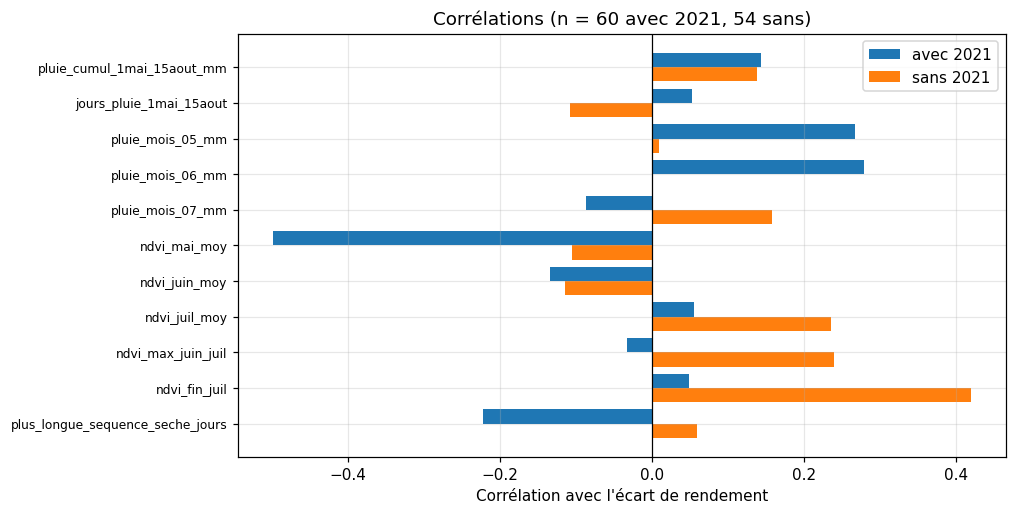

In [10]:
lignes = []
for f in FEATURES:
    r1, p1 = stats.pearsonr(d6[f + "_anom"], d6[CIBLE + "_anom"])
    d_no = d6[d6.annee != 2021]
    r2, p2 = stats.pearsonr(d_no[f + "_anom"], d_no[CIBLE + "_anom"])
    lignes.append({"variable": f, "r_avec_2021": r1, "p_avec_2021": p1, "r_sans_2021": r2, "p_sans_2021": p2})
corr = pd.DataFrame(lignes).set_index("variable")
display(corr.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(corr))
ax.barh(y - 0.2, corr.r_avec_2021, height=0.4, label="avec 2021")
ax.barh(y + 0.2, corr.r_sans_2021, height=0.4, label="sans 2021")
ax.set_yticks(y); ax.set_yticklabels(corr.index, fontsize=8); ax.invert_yaxis()
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Corrélation avec l'écart de rendement")
ax.set_title(f"Corrélations (n = {len(d6)} avec 2021, {len(d6) - 6} sans)"); ax.legend()
fig.savefig(f"{OUT_DIR}/fig4_correlations_avec_sans_2021.png", bbox_inches="tight", dpi=150)
plt.show()

**Attention à l'interprétation :** avec 9 à 11 variables testées, quelques corrélations « significatives » apparaissent par hasard (problème des comparaisons multiples). Une corrélation isolée ne prouve rien. Les 60 points ne sont de plus pas indépendants (même années, régions voisines).

## 9. Test de 2015 : les longues séquences sèches font-elles chuter le rendement ?

In [11]:
test = (df[df.annee.isin([2015, 2021]) & df.region.isin(REGIONS_EVALUATION)]
          [["region", "annee", "plus_longue_sequence_seche_jours", "pluie_cumul_1mai_15aout_mm",
            "ndvi_fin_juil", CIBLE, CIBLE + "_anom"]]
          .sort_values(["region", "annee"]).round(2))
test

,region,annee,plus_longue_sequence_seche_jours,pluie_cumul_1mai_15aout_mm,ndvi_fin_juil,rendement_calcule_kg_ha,rendement_calcule_kg_ha_anom
30,Maradi,2015,15.10,208.8,0.24,585.91,0.04
36,Maradi,2021,10.62,241.7,0.30,462.51,-0.18
50,Tahoua,2015,14.01,156.0,0.18,521.20,-0.02
56,Tahoua,2021,17.36,191.5,0.24,303.04,-0.43
60,Tillabéri,2015,9.01,286.4,0.21,447.27,0.05
66,Tillabéri,2021,9.19,248.0,0.25,231.92,-0.46
70,Zinder,2015,26.54,106.4,0.16,458.76,-0.02
76,Zinder,2021,26.33,150.1,0.20,318.47,-0.32


## 10. La baseline : moyenne historique de la région

La baseline prédit, pour une région et une année, **la moyenne des rendements des autres années de cette région** (validation « une année mise de côté »). Tout modèle de l'étape 4 devra faire mieux pour avoir un intérêt.

In [12]:
def baseline_loyo(d):
    lignes = []
    for r in REGIONS_EVALUATION:
        s = d[d.region == r].set_index("annee")[CIBLE]
        for a in s.index:
            pred = s.drop(a).mean()
            lignes.append({"region": r, "annee": a, "reel": s[a], "pred": pred,
                           "erreur_rel": abs(pred - s[a]) / s[a]})
    return pd.DataFrame(lignes)

base = baseline_loyo(df)
print(f"Erreur relative moyenne de la baseline : {100 * base.erreur_rel.mean():.1f} %")
print(f"  sans 2021 : {100 * base[base.annee != 2021].erreur_rel.mean():.1f} %")
print(f"  en 2021   : {100 * base[base.annee == 2021].erreur_rel.mean():.1f} %")
print()
print((100 * base.groupby("region").erreur_rel.mean()).round(1).rename("erreur moyenne (%)"))

Erreur relative moyenne de la baseline : 13.7 %
  sans 2021 : 8.2 %
  en 2021   : 63.4 %

region
Maradi        9.2
Tahoua       13.7
Tillabéri    20.9
Zinder       11.0
Name: erreur moyenne (%), dtype: float64


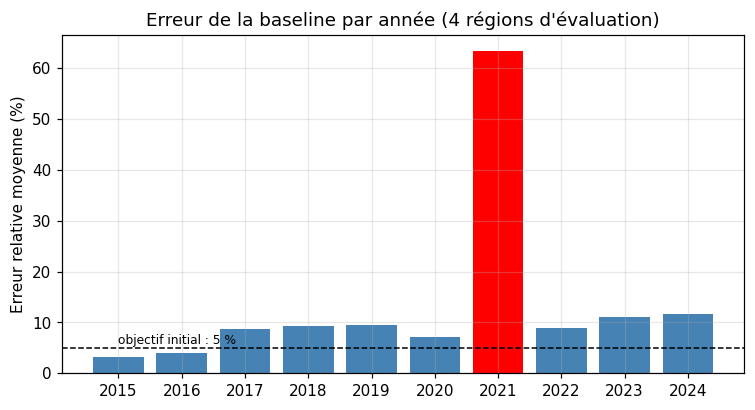

In [13]:
par_annee = 100 * base.groupby("annee").erreur_rel.mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(par_annee.index, par_annee.values, color=["red" if a == 2021 else "steelblue" for a in par_annee.index])
ax.axhline(5, color="k", ls="--", lw=1); ax.text(2015, 5.8, "objectif initial : 5 %", fontsize=8)
ax.set_xticks(range(2015, 2025)); ax.set_ylabel("Erreur relative moyenne (%)")
ax.set_title("Erreur de la baseline par année (4 régions d'évaluation)")
fig.savefig(f"{OUT_DIR}/fig5_erreur_baseline.png", bbox_inches="tight", dpi=150)
plt.show()

## 11. Sauvegarde du tableau assemblé

In [14]:
colonnes_modele = CLES + [CIBLE] + FEATURES
df[colonnes_modele].to_csv(f"{DATA_DIR}/jeu_assemble_2015_2024.csv", index=False)
print("Écrit :", f"{DATA_DIR}/jeu_assemble_2015_2024.csv", "|", df[colonnes_modele].shape)

Écrit : data/jeu_assemble_2015_2024.csv | (80, 14)


In [15]:
import os
print(os.getcwd())
print(os.path.exists("data/rendements_mil_niger_2015_2024.xlsx"))
print(os.path.exists("/data/rendements_mil_niger_2015_2024.xlsx"))

/content
True
True


In [16]:
import shutil
from google.colab import files
shutil.make_archive("a_envoyer_github", "zip", ".", "outputs")   # les 5 figures
files.download("a_envoyer_github.zip")
files.download("data/jeu_assemble_2015_2024.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>